In [40]:
# BLOQUE 0: IMPORTAR LIBRERIAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Scikit-learn: libreria de Machine Learning
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Configurar semilla para reproducibilidad buena practica
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
# Configurar estilo de matplotlib
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerias importadas")
print(f"Semilla de reproducibilidad: {RANDOM_STATE}")

Librerias importadas
Semilla de reproducibilidad: 42


In [41]:
# BLOQUE 1: CONSTRUIR LA SERIE DIARIA A PARTIR DEL DATASET LIMPIO
from google.colab import files

print("Selecciona dataset_limpio.csv")
subido = files.upload()
df_base = pd.read_csv(list(subido.keys())[0], parse_dates=["event_date"])

# Decision: el dataset esta por area y empresa para pronosticar se agrega
# por DIA
# (suma de todas las areas) igual que la serie diaria del caso modelo.
df = df_base.groupby("event_date").agg(
    incidentes=("incident_count", "sum"),
    despliegues=("deployment_count", "sum"),
    tickets=("ticket_count", "sum"),
    despliegues_fallidos=("failed_deployments", "sum")
).reset_index().rename(columns={"event_date": "fecha"})

df["dia_semana"] = df["fecha"].dt.dayofweek   # 0=lunes, 6=domingo
df["mes"] = df["fecha"].dt.month

print(f"\nSerie diaria creada: {df.shape[0]} dias, {df.shape[1]} columnas")
print(f"Desde {df['fecha'].min().date()} hasta {df['fecha'].max().date()}")
print("\nPrimeras 5 filas:")
print(df.head().to_string())

print(f"\nIncidentes diarios -> minimo: {df['incidentes'].min()}, maximo: {df['incidentes'].max()}, promedio: {df['incidentes'].mean():.2f}")

Selecciona dataset_limpio.csv


Saving dataset_limpio.csv to dataset_limpio (4).csv

Serie diaria creada: 181 dias, 7 columnas
Desde 2026-01-01 hasta 2026-06-30

Primeras 5 filas:
       fecha  incidentes  despliegues  tickets  despliegues_fallidos  dia_semana  mes
0 2026-01-01          19           73      292                     8           3    1
1 2026-01-02          21           83      287                     8           4    1
2 2026-01-03          16           76      279                     6           5    1
3 2026-01-04          20           78      257                     7           6    1
4 2026-01-05          21           81      292                    13           0    1

Incidentes diarios -> minimo: 12, maximo: 44, promedio: 22.10


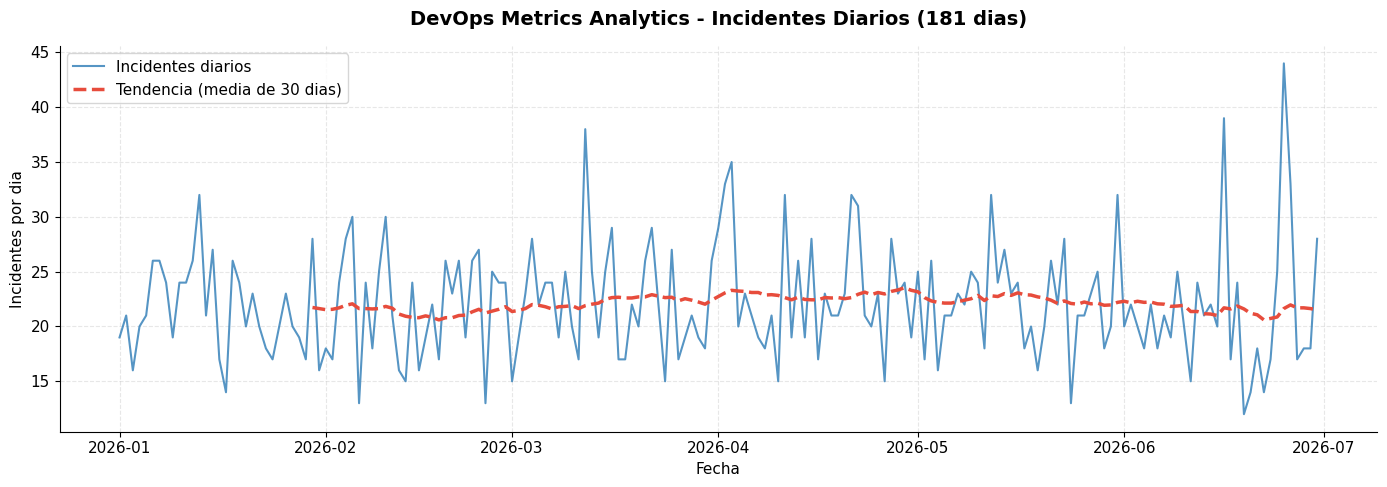


OBSERVACIONES DE LA SERIE:
   - Incidentes minimos en un dia: 12
   - Incidentes maximos en un dia: 44
   - Incidentes promedio por dia: 22.10


In [42]:
# BLOQUE 2: GRAFICO DE LA SERIE HISTORICA DE INCIDENTES


#NOTAS
# dibuja cuantos incidentes hubo cada dia (linea azul) y
# (linea roja) punteada con el promedio de los ultimos 30 dias.

# antes de predecir hay que revisamos los datos.
# Esta grafica permite ver si los incidentes van subiendo,
# bajando o se mantienen establescon el tiempo (la tendencia)

# La linea roja (media movil de 30 dias) suaviza los altibajos diarios para
# que se vea la direccion en general.
#Los primeros 29 dias no tienen linea roja
# porque aun no hay 30 dias de historia para promediar.

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df["fecha"], df["incidentes"],
        color='#2c7bb6', linewidth=1.5, alpha=0.8, label='Incidentes diarios')

df['tendencia_30'] = df['incidentes'].rolling(window=30).mean()
ax.plot(df["fecha"], df['tendencia_30'],
        color='#e74c3c', linewidth=2.5, linestyle='--', label='Tendencia (media de 30 dias)')

ax.set_title('DevOps Metrics Analytics - Incidentes Diarios (181 dias)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Incidentes por dia', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

print("\nOBSERVACIONES DE LA SERIE:")
print(f"   - Incidentes minimos en un dia: {df['incidentes'].min()}")
print(f"   - Incidentes maximos en un dia: {df['incidentes'].max()}")
print(f"   - Incidentes promedio por dia: {df['incidentes'].mean():.2f}")

Mediana de despliegues por dia: 82.0

INCIDENTES PROMEDIO SEGUN CANTIDAD DE DESPLIEGUES:
   Pocos despliegues (0):  19.30 incidentes por dia
   Muchos despliegues (1): 24.53 incidentes por dia

DIFERENCIA: 5.23 incidentes
IMPACTO: 27.1%


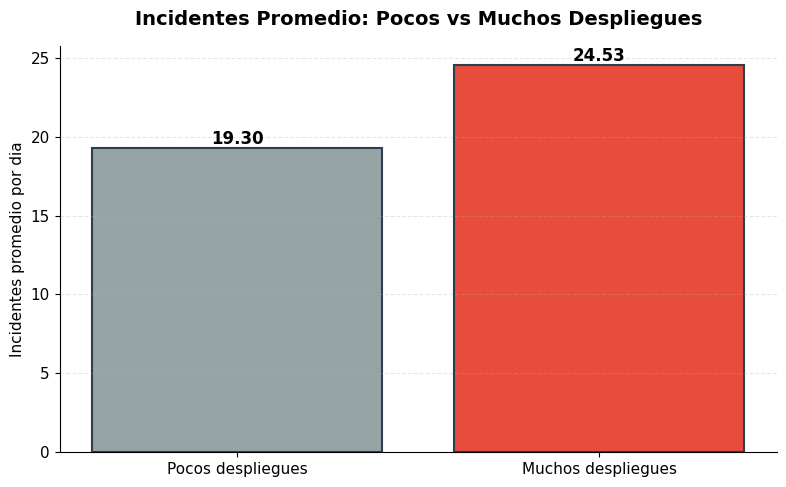


PATRONES OBSERVADOS:
1. Los dias con muchos despliegues tienen mas incidentes (correlacion = 0.63)
2. No hay tendencia con el tiempo: la serie es estable (correlacion con el tiempo = 0.02)
3. El dia de la semana influye poco: el promedio varia solo entre 20.7 y 23.7

HIPOTESIS:
La cantidad de despliegues del dia podria ser un predictor de incidentes;
el dia de la semana y el mes probablemente aportan poco a estas predicciones de incidentes.


In [43]:
# BLOQUE 3: COMPARAR INCIDENTES EN DIAS CON MUCHOS vs POCOS DESPLIEGUES
# | 5.1 VARIABLE OBJETIVO
#divide los 181 dias en dos grupos segun cuantos despliegues hubo
# (por encima o por debajo de la mediana) y compara el promedio de incidentes.


#Si los dias con mas despliegues son los que mas incidentes tienen
#entoces podemos anticipar problematicas/predecir

# mediana = el valor del medio.
#Los dias con despliegues >= mediana cuentan como "muchos despliegues" y el resto como "pocos".

mediana_desp = df["despliegues"].median()
df["despliegues_altos"] = (df["despliegues"] >= mediana_desp).astype(int)

promedio_desp = df.groupby("despliegues_altos")["incidentes"].mean()
#Pocos desp = 0, Muchos desp = 1
print(f"Mediana de despliegues por dia: {mediana_desp}")
print("\nINCIDENTES PROMEDIO SEGUN CANTIDAD DE DESPLIEGUES:")
print("=" * 50)
print(f"   Pocos despliegues (0):  {promedio_desp[0]:.2f} incidentes por dia")
print(f"   Muchos despliegues (1): {promedio_desp[1]:.2f} incidentes por dia")
print(f"\nDIFERENCIA: {promedio_desp[1] - promedio_desp[0]:.2f} incidentes")
print(f"IMPACTO: {((promedio_desp[1] / promedio_desp[0]) - 1) * 100:.1f}%")

# Grafico de barras comparativo
fig, ax = plt.subplots(figsize=(8, 5))
colores = ['#95a5a6', '#e74c3c']
barras = ax.bar(['Pocos despliegues', 'Muchos despliegues'],
                [promedio_desp[0], promedio_desp[1]],
                color=colores, edgecolor='#2c3e50', linewidth=1.5)

for barra, valor in zip(barras, [promedio_desp[0], promedio_desp[1]]):
    ax.text(barra.get_x() + barra.get_width()/2., barra.get_height(),
            f'{valor:.2f}', ha='center', va='bottom',
            fontsize=12, fontweight='bold')

ax.set_title('Incidentes Promedio: Pocos vs Muchos Despliegues',
             fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Incidentes promedio por dia', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.show()

# Datos que respaldan las observaciones (demostracion/evidednce)
corr_desp = df["incidentes"].corr(df["despliegues"])
corr_tiempo = np.corrcoef(np.arange(len(df)), df["incidentes"])[0, 1]
prom_semana = df.groupby("dia_semana")["incidentes"].mean()

print("\nPATRONES OBSERVADOS:")
print("=" * 50)
print(f"1. Los dias con muchos despliegues tienen mas incidentes (correlacion = {corr_desp:.2f})")
print(f"2. No hay tendencia con el tiempo: la serie es estable (correlacion con el tiempo = {corr_tiempo:.2f})")
print(f"3. El dia de la semana influye poco: el promedio varia solo entre {prom_semana.min():.1f} y {prom_semana.max():.1f}")
print("\nHIPOTESIS:")
print("La cantidad de despliegues del dia podria ser un predictor de incidentes;")
print("el dia de la semana y el mes probablemente aportan poco a estas predicciones de incidentes.")

In [44]:
# BLOQUE 4 | SECCION 5.2 DATASET DE MODELADO (parte 1: variables de rezago/lag)

#Problema- para predecir los incidentes de hoy, el modelo puede
# usar informacion de dias anteriores
#A esas variables estas
# les llama "de rezago" (lag en ingles).


#lag_1: incidentes de AYER
#lag_7: incidentes de hace 7 dias (el mismo dia de la semana pasada)
#media_movil_7: promedio de incidentes de los ULTIMOS 7 dias

df["lag_1"] = df["incidentes"].shift(1)
df["lag_7"] = df["incidentes"].shift(7)

df["media_movil_7"] = (
    df["incidentes"]
    .shift(1)            # excluye el dia actual (evita fuga)
    .rolling(window=7)   # toma 7 dias anteriores
    .mean()              # promedio
)
#evitar "fuga de datos"
# shift(1) mueve los valores una fila hacia abajo, asi cada fila solo ve el
# pasado.
#Sin shift(1), la media movil incluiria los incidentes de HOY.
#el modelo veria la respuesta que debe adivinar (No seria prediccion/trampa).

print("VARIABLES DE REZAGO CREADAS:")
print("=" * 70)
print(df[["fecha", "incidentes", "lag_1", "lag_7", "media_movil_7"]].head(10).to_string())
print("\n las primeras 7 filas tienen NaN (vacio) porque aun no hay 7 dias anteriroes disponibles")

# VERIFICACION DE FUGA (comprobamos con este ejemplo de 10 filas)
fila = 10
promedio_manual = df["incidentes"].iloc[fila-7:fila].mean()   # filas 3 a 9 dia 3 a 9
print(f"\nVERIFICACION en la fila {fila}:")
print(f"   media_movil_7 del dataframe: {df['media_movil_7'].iloc[fila]:.4f}")
print(f"   promedio manual de las filas {fila-7} a {fila-1}: {promedio_manual:.4f}")
print(f"   Coinciden: {np.isclose(df['media_movil_7'].iloc[fila], promedio_manual)}")

VARIABLES DE REZAGO CREADAS:
       fecha  incidentes  lag_1  lag_7  media_movil_7
0 2026-01-01          19    NaN    NaN            NaN
1 2026-01-02          21   19.0    NaN            NaN
2 2026-01-03          16   21.0    NaN            NaN
3 2026-01-04          20   16.0    NaN            NaN
4 2026-01-05          21   20.0    NaN            NaN
5 2026-01-06          26   21.0    NaN            NaN
6 2026-01-07          26   26.0    NaN            NaN
7 2026-01-08          24   26.0   19.0      21.285714
8 2026-01-09          19   24.0   21.0      22.000000
9 2026-01-10          24   19.0   16.0      21.714286

 las primeras 7 filas tienen NaN (vacio) porque aun no hay 7 dias anteriroes disponibles

VERIFICACION en la fila 10:
   media_movil_7 del dataframe: 22.8571
   promedio manual de las filas 3 a 9: 22.8571
   Coinciden: True


In [45]:
# BLOQUE 5 | SECCION 5.2 DATASET DE MODELADO (parte 2)
# 5.2.1 Variables predictoras (X)
#y  5.2.2 Variable objetivo (y)



#(5.2.1) eliminara las filas que no tienen historial
#(5.2.2) separa los datos en dos grupos:
#   X = las "pistas" para el modelo a mirar (V Predictoras)
#   y = lo que adivinara el modelo (V Objetivo: incidentes del dia)

print(f"Filas ANTES de eliminar NaN: {len(df)}")

# usamos subset=[...] para eliminar solo las filas sin lag.
#subset revisa vacios en las 3 columnas
# solo dropna deja 152 filas en vez de 174, perdiendo datos sin necesidad.
df_modelo = df.dropna(subset=["lag_1", "lag_7", "media_movil_7"]).copy().reset_index(drop=True)

print(f"Filas DESPUES de eliminar NaN: {len(df_modelo)}")
print(f"Filas eliminadas: {len(df) - len(df_modelo)} (los primeros 7 dias, sin historial)")
print(f"Periodo de modelado: {df_modelo['fecha'].iloc[0].date()} a {df_modelo['fecha'].iloc[-1].date()}")

# 5.2.1 Variables predictoras (X)
# VARIABLES PREDICTORAS: solo las que se conocen ANTES de que termine el dia
# dia de la semana (0=lunes / 6=domingo)
# mes del anio (1 a 6)
# despliegues del dia (SUPUESTOS: con antelacion,
# asi que se conocen al predecir es el equivalente a
# "promocion_activa" del caso modelo)
features = [
    "dia_semana",
    "mes",
    "despliegues",
    "lag_1",         # incidentes de ayer
    "lag_7",         # incidentes de hace 7 dias
    "media_movil_7"  # promedio de incidentes de los ultimos 7 dias (sin hoy)
]

# VARIABLES EXCLUIDAS Y Pq (documentacion RECORDATORIO 5.2.1):
# - tickets: los tickets llegan despueS de que ocurre el problema, no se
#   conocen al momento de predecir (fuga de datos)
# - despliegues_fallidos: solo se sabe cuando termina el dia (fuga de datos)
# - fecha: no es numerica ya esta representada por mes y dia_semana
# - tendencia_30 y despliegues_altos: solo se usaron para los graficos
#   (tendencia_30 incluye el dia actual y despliegues_altos repite la
#   informacion de despliegues)

X = df_modelo[features]
y = df_modelo["incidentes"]

print("\nVARIABLES DEFINIDAS:")
print("=" * 60)
print(f"Variables predictoras (X): {len(features)}")
for i, f in enumerate(features, 1):
    print(f"   {i}. {f}")
print("\nVariable objetivo (y): incidentes")
print("\nDimensiones:")
print(f"   X: {X.shape}")
print(f"   y: {y.shape}")
print(f"   Valores nulos en X: {X.isnull().sum().sum()}")

Filas ANTES de eliminar NaN: 181
Filas DESPUES de eliminar NaN: 174
Filas eliminadas: 7 (los primeros 7 dias, sin historial)
Periodo de modelado: 2026-01-08 a 2026-06-30

VARIABLES DEFINIDAS:
Variables predictoras (X): 6
   1. dia_semana
   2. mes
   3. despliegues
   4. lag_1
   5. lag_7
   6. media_movil_7

Variable objetivo (y): incidentes

Dimensiones:
   X: (174, 6)
   y: (174,)
   Valores nulos en X: 0


In [46]:
# BLOQUE 6 | SECCION 5.3 DIVISION DE DATOS (SPLIT TEMPORAL 80/20)

# separa datos en dos partes:
#ENTRENAMIENTO (80%): los dias donde el modelo "aprende"
#PRUEBA (20%): los dias finales, que el modelo nunca vio, para evaluar,


#Utilizamos por orden cronologico y no aleatorio ya que (fuga de datos)
#Si mezclaramos al azar si entrenamos dias de junio y "predeceriamos"
#dias de febrero. Por ende por logica lo hacemos cronologicamente asi
#"predice" dias que no han ocurrido

#80/20 ya que es una serie corta de 174 dias utiles en este caso es la mejor opcion.
corte = int(len(df_modelo) * 0.80)

X_train = X.iloc[:corte]
X_test = X.iloc[corte:]

y_train = y.iloc[:corte]
y_test = y.iloc[corte:]

# Se guardan las fechas de prueba para usarlas despues en los graficos
fecha_test = df_modelo["fecha"].iloc[corte:]

print("SPLIT TEMPORAL 80/20")
print("=" * 60)
print(f"Total de registros: {len(df_modelo)}")
print(f"Entrenamiento: {len(X_train)} registros (80%)")
print(f"Prueba: {len(X_test)} registros (20%)")

print("\nRango de ENTRENAMIENTO:")
print(f"   Desde: {df_modelo['fecha'].iloc[0].date()}")
print(f"   Hasta: {df_modelo['fecha'].iloc[corte-1].date()}")

print("\nRango de PRUEBA:")
print(f"   Desde: {df_modelo['fecha'].iloc[corte].date()}")
print(f"   Hasta: {df_modelo['fecha'].iloc[-1].date()}")

# VERIFICACION
#las fechas de prueba deben ser posteriores a las de entrenamiento
print("\nVERIFICACION:")
print(f"   Ultima fecha entrenamiento: {df_modelo['fecha'].iloc[corte-1].date()}")
print(f"   Primera fecha prueba: {df_modelo['fecha'].iloc[corte].date()}")
print(f"   Prueba despues de entrenamiento? {df_modelo['fecha'].iloc[corte] > df_modelo['fecha'].iloc[corte-1]}")

SPLIT TEMPORAL 80/20
Total de registros: 174
Entrenamiento: 139 registros (80%)
Prueba: 35 registros (20%)

Rango de ENTRENAMIENTO:
   Desde: 2026-01-08
   Hasta: 2026-05-26

Rango de PRUEBA:
   Desde: 2026-05-27
   Hasta: 2026-06-30

VERIFICACION:
   Ultima fecha entrenamiento: 2026-05-26
   Primera fecha prueba: 2026-05-27
   Prueba despues de entrenamiento? True


In [47]:
# BLOQUE 7 | SECCION 5.4 MODELO IMPLEMENTADO (p 1: baseline)

#BASELINE: el "modelo mas basico".
# predice el promedio de incidentes
# del entrenamiento pero sin mirar ninguna variable.
# esto es util para medir si el MODELO es util ya que si el modelo es
# peor que la baseline no aporta  y solo termina siendo complejo

# METRICAS :
# - MAE:  error promedio en incidentes
# (cuantos incidentes se equivoca en promedio)

# - RMSE:
# MAE, pero castiga mas los errores grandes

# - R2:
# 0 = no mejora al promedio, 1 = perfecto (negativo = peor que el promedio)

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

mae_base = mean_absolute_error(y_test, pred_baseline)
rmse_base = mean_squared_error(y_test, pred_baseline) ** 0.5
r2_base = r2_score(y_test, pred_baseline)

print("BASELINE (promedio del entrenamiento)")
print("=" * 60)
print(f"Promedio del entrenamiento: {y_train.mean():.2f} incidentes por dia")
print("\nMETRICAS DEL BASELINE:")
print(f"   MAE:  {mae_base:.2f} incidentes")
print(f"   RMSE: {rmse_base:.2f} incidentes")
print(f"   R2:   {r2_base:.4f}")

BASELINE (promedio del entrenamiento)
Promedio del entrenamiento: 22.22 incidentes por dia

METRICAS DEL BASELINE:
   MAE:  4.85 incidentes
   RMSE: 6.65 incidentes
   R2:   -0.0039


In [48]:
# BLOQUE 8 | SECCION 5.4 MODELO IMPLEMENTADO (parte 2: regresion lineal)
#
# REGRESION LINEAL:el modelo aprende una formula para adivinar los incidentes
# incidentes = a + b1*despliegues + b2*dia_semana + b3*lag_1 + ...
# Cada b (coeficiente) dice cuantos incidentes suben o bajan
# cuando esa variable sube 1.

# predicira (cuantos incidentes habra en un dia)

# .fit() = el modelo "aprende" con los dias de entrenamiento
# .predict() = adivina los incidentes de los dias de PRUEBA (que nunca vio)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)

print("REGRESION LINEAL")
print("=" * 60)
print("\nMETRICAS DEL MODELO:")
print(f"   MAE:  {mae:.2f} incidentes")
print(f"   RMSE: {rmse:.2f} incidentes")
print(f"   R2:   {r2:.4f}")

REGRESION LINEAL

METRICAS DEL MODELO:
   MAE:  4.15 incidentes
   RMSE: 5.49 incidentes
   R2:   0.3159


In [49]:
# BLOQUE 9 | SECCION 5.5 METRICAS DE EVALUACION

# juntamos en una sola tabla las metricas del baseline y del modelo,
# y calculo en que porcentaje el modelo mejora a comparacion del baseline.
# es la prueba de que el modelo vale la pena.

#  - MAE y RMSE: mientras MAS BAJOS, mejor (son errores, en incidentes por dia)
# - R2: mientras MAS ALTO, mejor (0 = no explica nada, 1 = explica todo)

comparacion = pd.DataFrame({
    "Modelo": ["Baseline (promedio)", "Regresion Lineal"],
    "MAE": [mae_base, mae],
    "RMSE": [rmse_base, rmse],
    "R2": [r2_base, r2]
}).round({"MAE": 2, "RMSE": 2, "R2": 4})

print("COMPARACION BASELINE vs MODELO:")
print("=" * 70)
print(comparacion.to_string(index=False))

# Porcentaje de mejora: cuanto se redujo el error respecto al baseline
mejora_mae = ((mae_base - mae) / mae_base) * 100
mejora_rmse = ((rmse_base - rmse) / rmse_base) * 100

print("\nMEJORAS DEL MODELO vs BASELINE:")
print(f"   MAE:  {mejora_mae:.1f}% de mejora")
print(f"   RMSE: {mejora_rmse:.1f}% de mejora")

# INTERPRETACION.
#El baseline(promedio) tiene R2 cercano a 0: predecir siempre el promedio
#   no explica ninguna variacion, como era de esperar.
#El modelo reduce el error promedio de 4.85 a 4.15 incidentes por dia y
#explica cerca del 32% de la variacion de los incidentes (R2 = 0.32).
#Es una mejora minimo pero cumple: el resto de la variacion (68%) depende de
#   factores que este dataset no tiene (limitaciones, 5.6.2).
print("\nINTERPRETACION:")
print(f"   El modelo explica cerca del {r2*100:.0f}% de la variacion de los incidentes diarios")
print(f"   y reduce el error promedio de {mae_base:.2f} a {mae:.2f} incidentes por dia.")

COMPARACION BASELINE vs MODELO:
             Modelo  MAE  RMSE      R2
Baseline (promedio) 4.85  6.65 -0.0039
   Regresion Lineal 4.15  5.49  0.3159

MEJORAS DEL MODELO vs BASELINE:
   MAE:  14.5% de mejora
   RMSE: 17.5% de mejora

INTERPRETACION:
   El modelo explica cerca del 32% de la variacion de los incidentes diarios
   y reduce el error promedio de 4.85 a 4.15 incidentes por dia.


In [50]:
# BLOQUE 10 | SECCION 5.6.1 INTERPRETACION PRELIMINAR (coeficientes)

# muestra la "formula" que aprendio el modelo. Cada variable tiene un
# coeficiente: cuantos incidentes cambian cuando esa variable sube 1 unidad
# (positivo = sube los incidentes, negativo = los baja).


# las variables tienen escalas distintas (despliegues va de ~60 a
# ~120, dia_semana de 0 a 6), asi que comparar coeficientes a simple vista
# engana. Por eso se agrega "efecto_tipico" = coeficiente x desviacion estandar
# (cuantos incidentes cambia la prediccion con una variacion NORMAL de esa
# variable). Esa columna SI es comparable entre variables.


coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.coef_
}).sort_values("coeficiente", key=abs, ascending=False)

desviaciones = X_train.std()
coeficientes["efecto_tipico"] = coeficientes["coeficiente"] * coeficientes["variable"].map(desviaciones)

#importancia sengun
# Alta >= 1 | Media entre 0.3 y 1 | Baja < 0.3
def clasificar(valor):
    valor = abs(valor)
    if valor >= 1:
        return "Alta"
    elif valor >= 0.3:
        return "Media"
    return "Baja"

coeficientes["importancia"] = coeficientes["efecto_tipico"].apply(clasificar)

print("COEFICIENTES DEL MODELO:")
print("=" * 70)
print(coeficientes.round(4).to_string(index=False))

print(f"\nIntercepto (b0): {modelo.intercept_:.2f}")
print("(el intercepto es el punto de partida de la formula; por si solo no tiene interpretacion)")

# interpretacion (recordatorio documentacion avances):
# despliegues es la unica variable con importancia ALTA: cada despliegue
#   adicional en el dia suma cerca de 0.32 incidentes (+10 despliegues = +3.2 incidentes).
# dia_semana, mes, lag_1, lag_7 y media_movil_7 tienen efecto muy pequeno:
#   el pasado reciente y el calendario casi no ayudan a predecir.
# Esto confirma lo observado en el Bloque 3 (pocos vs muchos despliegues) y es
#   coherente con el Bloque 2 (la serie no tiene tendencia ni ciclo semanal claro).
print("\nINTERPRETACION:")
print("   -''despliegues' es la variable que mas pesa: 0.32 incidentes extra por cada despliegue")
print("   - Las demas variables (calendario y rezagos) tienen un efecto muy pequeno")

COEFICIENTES DEL MODELO:
     variable  coeficiente  efecto_tipico importancia
  despliegues       0.3207         3.1766        Alta
media_movil_7      -0.1313        -0.2130        Baja
   dia_semana      -0.0656        -0.1320        Baja
          mes       0.0361         0.0494        Baja
        lag_7      -0.0086        -0.0409        Baja
        lag_1       0.0036         0.0172        Baja

Intercepto (b0): -1.50
(el intercepto es el punto de partida de la formula; por si solo no tiene interpretacion)

INTERPRETACION:
   -''despliegues' es la variable que mas pesa: 0.32 incidentes extra por cada despliegue
   - Las demas variables (calendario y rezagos) tienen un efecto muy pequeno


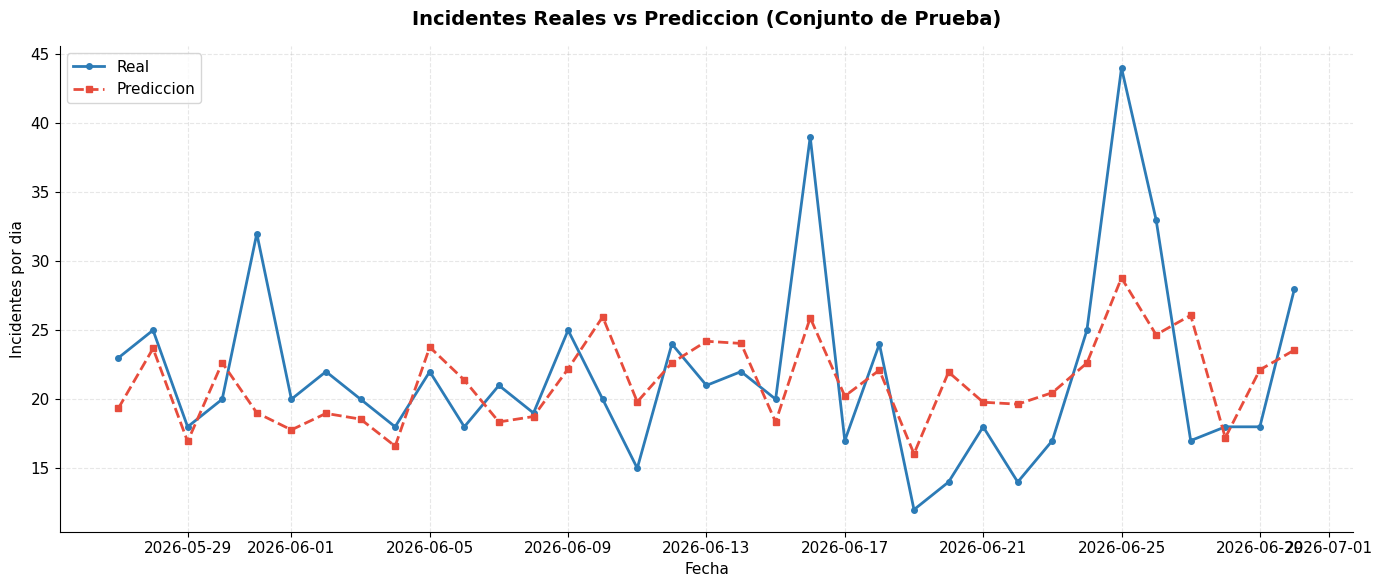

In [51]:
# BLOQUE 11 | SECCION 5.6 INTERPRETACION (graficos de evaluacion)

# dos graficos para ver que tan bien fue la prediccion del modelo en los
# 35 dias de prueba (27 may a 30 jun), que el modelo nunca vio al entrenar.

# GRAFICO 1 (lineas): cada dia, el valor REAL (azul) contra la PREDICCION (rojo).
#   Si las lineas van juntas, el modelo acierta.

# ---- GRAFICO 1: real vs prediccion en el tiempo ----
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(fecha_test, y_test.values,
        label='Real', color='#2c7bb6', linewidth=2, marker='o', markersize=4)
ax.plot(fecha_test, pred,
        label='Prediccion', color='#e74c3c', linewidth=2,
        linestyle='--', marker='s', markersize=4)

ax.set_title('Incidentes Reales vs Prediccion (Conjunto de Prueba)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Incidentes por dia', fontsize=11)
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


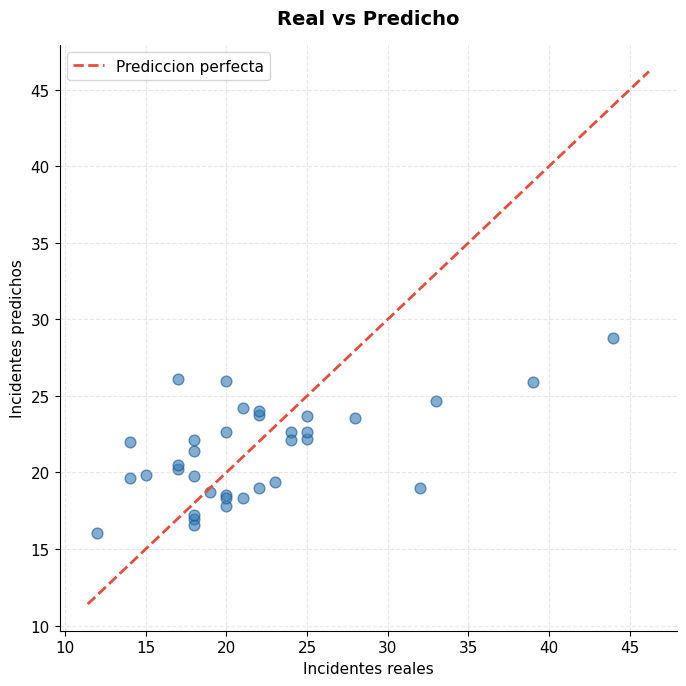

OBSERVACIONES:
   -Los incidentes reales van de 12 a 44 por dia
   -Las predicciones van de 16.0 a 28.8: el modelo
    sigue el nivel general pero no alcanza los picos extremos
   -Si los puntos estan dispersos alrededor de la linea roja, el modelo
     acierta en promedio pero se equivoca en dias puntuales


In [52]:
# BLOQUE 11 | SECCION 5.6 INTERPRETACION (graficos de evaluacion)

# GRAFICO 2 (dispersion): cada punto es un dia; en el eje X el valor real y en
#  el Y la prediccion. La linea roja diagonal es la "prediccion perfecta":
#  mientras mas cerca de ella esten los puntos, mejor.

# ---- GRAFICO 2: real vs predicho (dispersion) ----
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(y_test, pred, alpha=0.6, color='#2c7bb6', edgecolors='#1a5490', s=60)

# Linea de referencia ideal (y = x): aqui real y predicho serian iguales
lim_min = min(y_test.min(), pred.min()) * 0.95
lim_max = max(y_test.max(), pred.max()) * 1.05
ax.plot([lim_min, lim_max], [lim_min, lim_max],
        color='#e74c3c', linestyle='--', linewidth=2, label='Prediccion perfecta')

ax.set_xlabel('Incidentes reales', fontsize=11)
ax.set_ylabel('Incidentes predichos', fontsize=11)
ax.set_title('Real vs Predicho', fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

# OBSERVACIONES (con datos reales)
print("OBSERVACIONES:")
print(f"   -Los incidentes reales van de {y_test.min()} a {y_test.max()} por dia")
print(f"   -Las predicciones van de {pred.min():.1f} a {pred.max():.1f}: el modelo")
print("    sigue el nivel general pero no alcanza los picos extremos")
print("   -Si los puntos estan dispersos alrededor de la linea roja, el modelo")
print("     acierta en promedio pero se equivoca en dias puntuales")

In [ ]:
# BLOQUE 12 | SECCION 5.6 INTERPRETACION (analisis de residuos)

# RESIDUO: el error del modelo en un dia = real - prediccion.
# Residuo POSITIVO: el modelo no tiene suficientes datos
# (hubo mas incidentes de los predichos)
# Residuo NEGATIVO: el modelo se paso (hubo menos incidentes de los predichos)

# revisar DONDE y CUANTO se equivoca el modelo. Un buen modelo
# tiene residuos pequenos y repartidos de forma pareja (positivos y negativos).

resultados = pd.DataFrame({
    "fecha": fecha_test.values,
    "real": y_test.values,
    "prediccion": pred
})
resultados["residuo"] = resultados["real"] - resultados["prediccion"]
resultados["error_abs"] = resultados["residuo"].abs()

columnas_redondeo = {"prediccion": 2, "residuo": 2, "error_abs": 2}

print("PRIMEROS 10 RESIDUOS:")
print(resultados.head(10).round(columnas_redondeo).to_string(index=False))

print("\nESTADISTICAS DE RESIDUOS:")
print(f"   Residuo promedio: {resultados['residuo'].mean():.2f} incidentes")
print(f"   Residuo minimo:   {resultados['residuo'].min():.2f} incidentes")
print(f"   Residuo maximo:   {resultados['residuo'].max():.2f} incidentes")

print("\nTOP 5 ERRORES MAS GRANDES:")
print(resultados.nlargest(5, 'error_abs').round(columnas_redondeo).to_string(index=False))

dias_buenos = (resultados["error_abs"] <= 5).sum()
print(f"\nDias con error de 5 incidentes o menos: {dias_buenos} de {len(resultados)}")

# INTERPRETACION (word)
# - El residuo promedio es cercano a 0: el modelo no se equivoca siempre hacia el mismo lado.
# - Los errores grandes ocurren casi todos en dias con picos de incidentes
#   el modelo predice valores suaves y no anticipa los dias extremos.


PRIMEROS 10 RESIDUOS:
     fecha  real  prediccion  residuo  error_abs
2026-05-27    23       19.35     3.65       3.65
2026-05-28    25       23.68     1.32       1.32
2026-05-29    18       16.94     1.06       1.06
2026-05-30    20       22.64    -2.64       2.64
2026-05-31    32       19.01    12.99      12.99
2026-06-01    20       17.78     2.22       2.22
2026-06-02    22       18.97     3.03       3.03
2026-06-03    20       18.56     1.44       1.44
2026-06-04    18       16.60     1.40       1.40
2026-06-05    22       23.77    -1.77       1.77

ESTADISTICAS DE RESIDUOS:
   Residuo promedio: 0.54 incidentes
   Residuo minimo:   -9.08 incidentes
   Residuo maximo:   15.21 incidentes

TOP 5 ERRORES MAS GRANDES:
     fecha  real  prediccion  residuo  error_abs
2026-06-25    44       28.79    15.21      15.21
2026-06-16    39       25.90    13.10      13.10
2026-05-31    32       19.01    12.99      12.99
2026-06-27    17       26.08    -9.08       9.08
2026-06-26    33       24.

In [54]:
# BLOQUE 14 | ANEXO: GUARDAR Y DESCARGAR RESULTADOS

from pathlib import Path
from google.colab import files

BASE_DIR = Path("/content/")
(BASE_DIR / "datos" / "procesados").mkdir(parents=True, exist_ok=True)
(BASE_DIR / "documentos").mkdir(parents=True, exist_ok=True)

ruta_pred = BASE_DIR / "datos" / "procesados" / "predicciones_guia08_equipo.csv"
resultados.to_csv(ruta_pred, index=False, encoding="utf-8")
print(f"Predicciones guardadas: {ruta_pred.name}")

ruta_metricas = BASE_DIR / "documentos" / "metricas_guia08_equipo.csv"
comparacion.to_csv(ruta_metricas, index=False, encoding="utf-8")
print(f"Metricas guardadas: {ruta_metricas.name}")

ruta_coef = BASE_DIR / "documentos" / "coeficientes_guia08_equipo.csv"
coeficientes.round(4).to_csv(ruta_coef, index=False, encoding="utf-8")
print(f"Coeficientes guardados: {ruta_coef.name}")

for ruta in [ruta_pred, ruta_metricas, ruta_coef]:
    files.download(str(ruta))
print("\nArchivos descargados")

Predicciones guardadas: predicciones_guia08_equipo.csv
Metricas guardadas: metricas_guia08_equipo.csv
Coeficientes guardados: coeficientes_guia08_equipo.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Archivos descargados
